# Deteksi Fraud Kartu Kredit dengan Metode Ensemble

Notebook ini membandingkan beberapa pendekatan untuk menangani **class imbalance** pada dataset
[Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud):

| Model | Cara menangani imbalance |
|---|---|
| Random Forest | Tanpa penanganan (baseline) |
| Random Forest | SMOTE (oversampling kelas minoritas) |
| Random Forest | Random Undersampling (kelas mayoritas) |
| XGBoost | Tanpa penanganan (baseline) |
| XGBoost | Cost-sensitive learning (`scale_pos_weight`) |

**Alur:** load data → eksplorasi → split data → resampling → training → evaluasi & perbandingan.

## 1. Import Library

In [1]:
import os

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             classification_report, confusion_matrix,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

RANDOM_STATE = 42

## 2. Load Dataset

Dataset diunduh langsung dari Kaggle memakai `kagglehub` (hasil unduhan di-cache secara lokal).
Berisi transaksi kartu kredit pemegang kartu Eropa; fitur `V1`–`V28` adalah hasil transformasi PCA
(dianonimkan), sedangkan `Time` dan `Amount` adalah fitur asli. Target `Class`: `1` = fraud, `0` = normal.

In [2]:
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "creditcard.csv"))
df.shape

Path to dataset files: /home/irzam/.cache/kagglehub/datasets/mlg-ulb/creditcardfraud/versions/3


(284807, 31)

## 3. Eksplorasi Data

In [3]:
display(df.head())
display(df.describe())
df.info()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

- Terdapat **284.807 transaksi** dan **31 kolom**, tanpa nilai kosong (*non-null* di semua kolom).
- Rata-rata `V1`–`V28` mendekati 0, konsisten dengan hasil PCA.
- `Amount` memiliki rentang sangat lebar (0 hingga ±25.691), dengan median jauh di bawah rata-rata (distribusi condong ke kanan).
- Rata-rata `Class` hanya ±0,0017, menandakan fraud sangat jarang terjadi.

## 4. Distribusi Kelas & Pembagian Data

Pada kasus fraud, kelas positif sangat sedikit. Akurasi menjadi metrik yang menyesatkan
(model yang selalu menebak "normal" sudah akurat >99%), sehingga evaluasi nanti berfokus pada
**precision, recall, F1, dan PR-AUC**.

Data dibagi 80% train / 20% test dengan `stratify=y` agar proporsi fraud sama di kedua bagian.

       jumlah  persen
Class                
0      284315  99.827
1         492   0.173


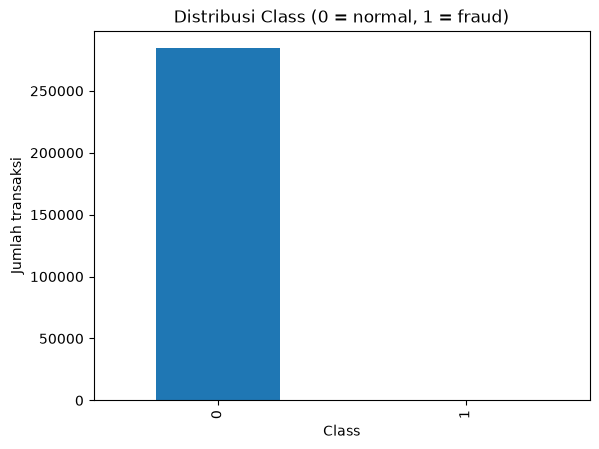

In [4]:
counts = df["Class"].value_counts()
print(pd.DataFrame({"jumlah": counts, "persen": (counts / len(df) * 100).round(3)}))

counts.plot(kind="bar", title="Distribusi Class (0 = normal, 1 = fraud)")
plt.xlabel("Class"); plt.ylabel("Jumlah transaksi")
plt.show()

X, y = df.drop(columns="Class"), df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

## 5. Penanganan Class Imbalance & Training Random Forest

Dua teknik resampling dibandingkan dengan baseline tanpa penanganan:

- **SMOTE**: membuat sampel sintetis kelas minoritas (fraud) lewat interpolasi antar tetangga terdekat sehingga kedua kelas seimbang.
- **Random Undersampling**: membuang sampel acak dari kelas mayoritas hingga seimbang dengan kelas minoritas. Cepat, tetapi banyak informasi terbuang.

> **Penting:** resampling hanya diterapkan pada **data train**. Data test dibiarkan apa adanya
> agar evaluasi mencerminkan distribusi dunia nyata dan tidak terjadi *data leakage*.

In [5]:
X_sm, y_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
X_us, y_us = RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(X_train, y_train)

def make_rf():
    return RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)

models = {
    "RF (baseline)": make_rf().fit(X_train, y_train),
    "RF + SMOTE": make_rf().fit(X_sm, y_sm),
    "RF + Undersampling": make_rf().fit(X_us, y_us),
}

## 6. Training XGBoost

Selain resampling, imbalance juga bisa ditangani lewat **cost-sensitive learning**:
`scale_pos_weight = jumlah negatif / jumlah positif` membuat kesalahan pada kelas fraud
dihukum lebih berat saat training, tanpa mengubah datanya.
`eval_metric="aucpr"` dipilih karena lebih informatif daripada AUC-ROC pada data yang sangat tidak seimbang.

In [6]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {spw:.1f}")

xgb_params = dict(
    n_estimators=300, learning_rate=0.1, max_depth=6,
    tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, eval_metric="aucpr",
)

models["XGBoost (baseline)"] = XGBClassifier(**xgb_params).fit(X_train, y_train)
models["XGBoost (cost-sensitive)"] = XGBClassifier(**xgb_params, scale_pos_weight=spw).fit(X_train, y_train)

scale_pos_weight = 577.3


## 7. Evaluasi Model

Setiap model dievaluasi pada data test asli. Metrik yang dilaporkan:
- **Precision**: dari transaksi yang diprediksi fraud, berapa yang benar-benar fraud.
- **Recall**: dari seluruh fraud sebenarnya, berapa yang berhasil terdeteksi.
- **ROC-AUC** dan **PR-AUC**: kualitas peringkat probabilitas; PR-AUC lebih sensitif pada kelas minoritas.
- **Confusion matrix**: rincian TN / FP / FN / TP.


=== RF (baseline) ===
              precision    recall  f1-score   support

           0     0.9997    0.9999    0.9998     56864
           1     0.9412    0.8163    0.8743        98

    accuracy                         0.9996     56962
   macro avg     0.9704    0.9081    0.9371     56962
weighted avg     0.9996    0.9996    0.9996     56962



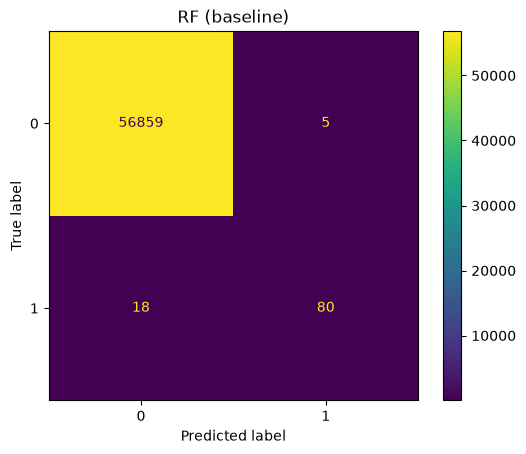


=== RF + SMOTE ===
              precision    recall  f1-score   support

           0     0.9997    0.9997    0.9997     56864
           1     0.8351    0.8265    0.8308        98

    accuracy                         0.9994     56962
   macro avg     0.9174    0.9131    0.9152     56962
weighted avg     0.9994    0.9994    0.9994     56962



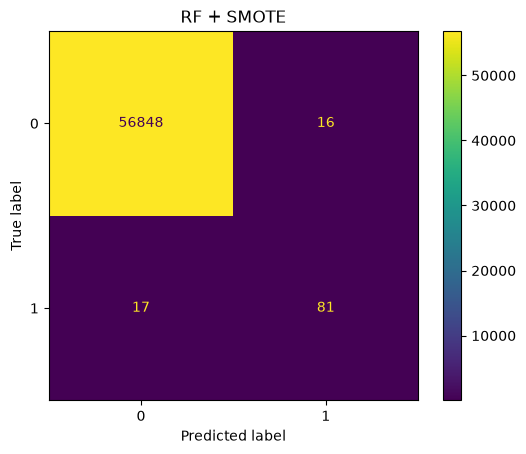


=== RF + Undersampling ===
              precision    recall  f1-score   support

           0     0.9999    0.9642    0.9817     56864
           1     0.0423    0.9184    0.0809        98

    accuracy                         0.9641     56962
   macro avg     0.5211    0.9413    0.5313     56962
weighted avg     0.9982    0.9641    0.9801     56962



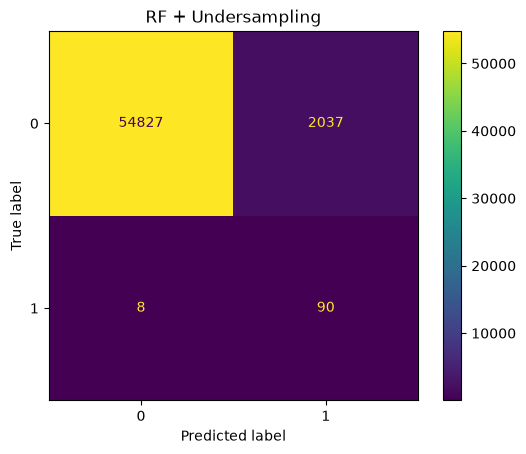


=== XGBoost (baseline) ===
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9398    0.7959    0.8619        98

    accuracy                         0.9996     56962
   macro avg     0.9697    0.8979    0.9308     56962
weighted avg     0.9995    0.9996    0.9995     56962



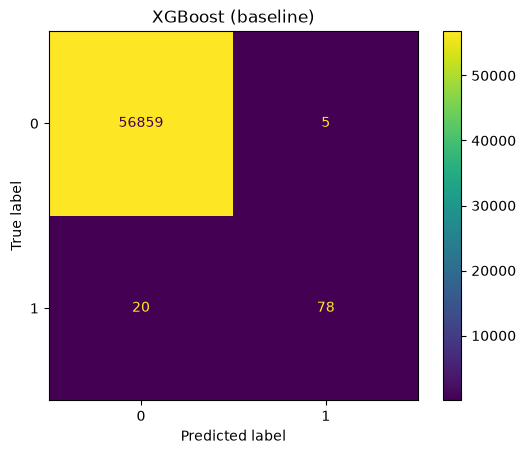


=== XGBoost (cost-sensitive) ===
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56864
           1     0.8925    0.8469    0.8691        98

    accuracy                         0.9996     56962
   macro avg     0.9461    0.9234    0.9344     56962
weighted avg     0.9996    0.9996    0.9996     56962



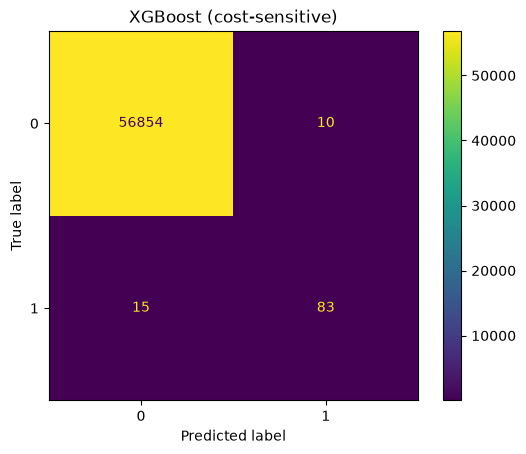

In [7]:
def evaluate(name, model):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    print(f"\n=== {name} ===")
    print(classification_report(y_test, pred, digits=4))

    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
    plt.title(name)
    plt.show()

    report = classification_report(y_test, pred, output_dict=True)["1"]
    return {
        "Model": name,
        "Precision": report["precision"],
        "Recall": report["recall"],
        "F1": report["f1-score"],
        "ROC-AUC": roc_auc_score(y_test, proba),
        "PR-AUC": average_precision_score(y_test, proba),
    }

results = [evaluate(name, model) for name, model in models.items()]

## 8. Perbandingan Model

Tabel ringkasan metrik untuk kelas fraud (`Class = 1`), diurutkan berdasarkan PR-AUC.

,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,
XGBoost (cost-sensitive),0.8925,0.8469,0.8691,0.9673,0.8852
RF + SMOTE,0.8351,0.8265,0.8308,0.9644,0.8747
RF (baseline),0.9412,0.8163,0.8743,0.9630,0.8734
XGBoost (baseline),0.9398,0.7959,0.8619,0.9628,0.8485
RF + Undersampling,0.0423,0.9184,0.0809,0.9777,0.6953


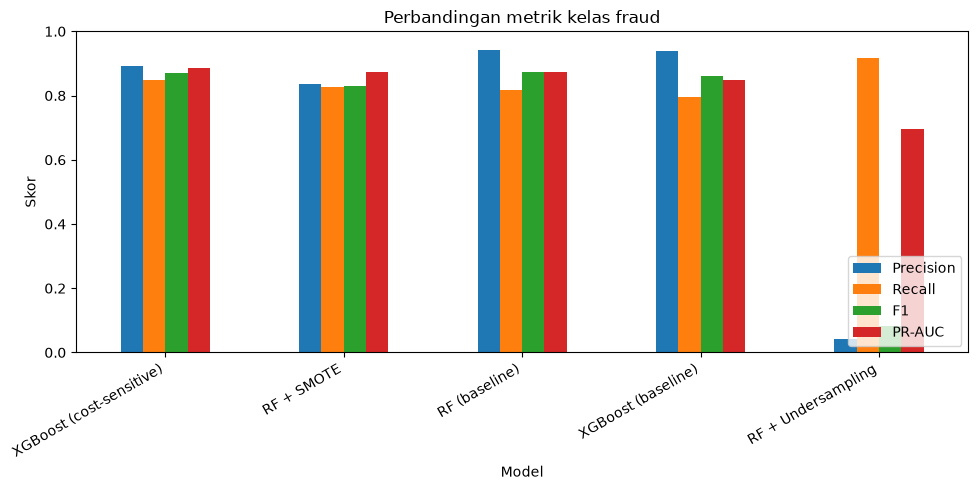

In [8]:
summary = pd.DataFrame(results).set_index("Model").sort_values("PR-AUC", ascending=False)
display(summary.round(4))

summary[["Precision", "Recall", "F1", "PR-AUC"]].plot(
    kind="bar", figsize=(10, 5), title="Perbandingan metrik kelas fraud"
)
plt.ylabel("Skor"); plt.ylim(0, 1); plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9. Kesimpulan

Isi setelah notebook dijalankan, dengan memperhatikan trade-off berikut:

- **Baseline** biasanya precision tinggi namun recall lebih rendah (banyak fraud terlewat).
- **SMOTE / Undersampling** cenderung menaikkan recall, tetapi menurunkan precision (lebih banyak *false positive*); undersampling paling ekstrem karena membuang banyak data normal.
- **XGBoost cost-sensitive** menggeser keseimbangan precision–recall tanpa mengubah data training.
- Pilihan model terbaik bergantung pada biaya kesalahan: melewatkan fraud (FN) umumnya lebih mahal daripada memblokir transaksi sah (FP), sehingga recall dan PR-AUC patut menjadi prioritas.